Original Dataset Shape: (750117, 9)

Missing values BEFORE cleaning:
Global_active_power      3942
Global_reactive_power    3942
Voltage                  3942
Global_intensity         3943
Sub_metering_1           3943
Sub_metering_2           3943
Sub_metering_3           3943
dtype: int64

Dataset shape after initial cleaning: (746174, 7)

Hourly dataset shape after NaN handling: (12503, 7)
Any NaNs left? 0


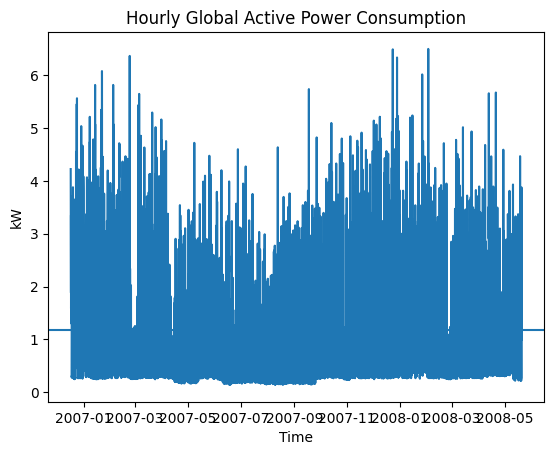

Mean Global Active Power (kW): 1.169


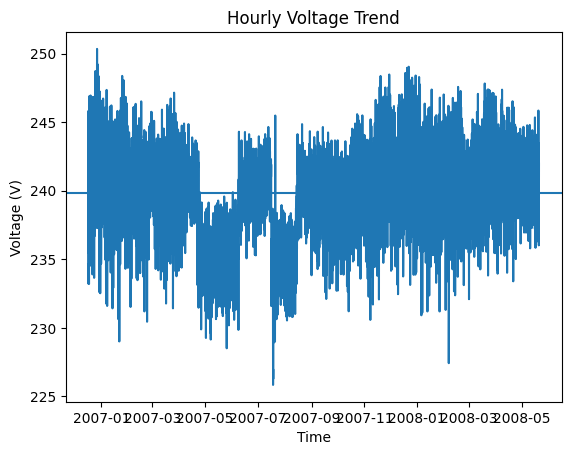

Mean Voltage (V): 239.82


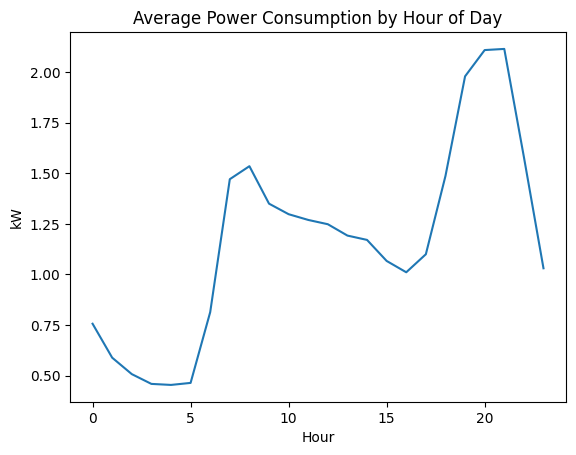

Peak Hour Consumption (kW): 2.114


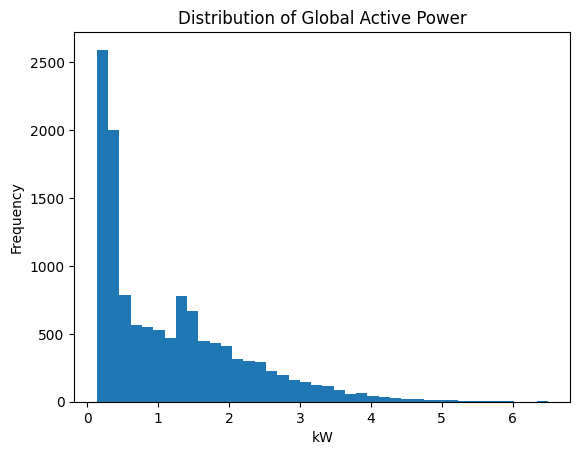

Median Power Consumption (kW): 0.86


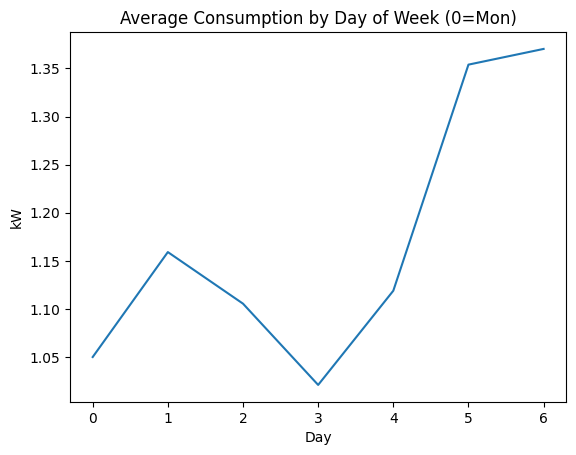

Highest weekday consumption (kW): 1.37


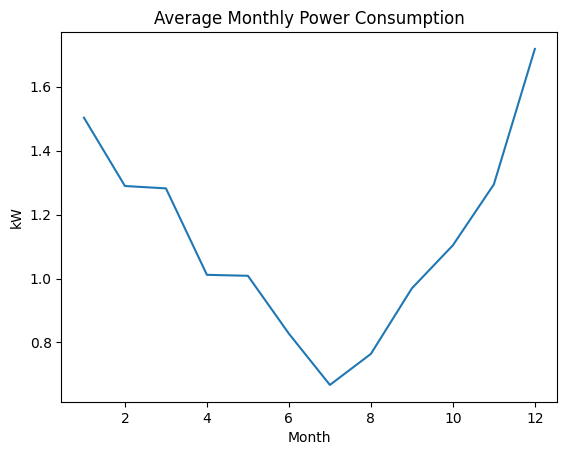

Highest monthly consumption (kW): 1.718
Training samples: (10002, 5)
Testing samples: (2501, 5)


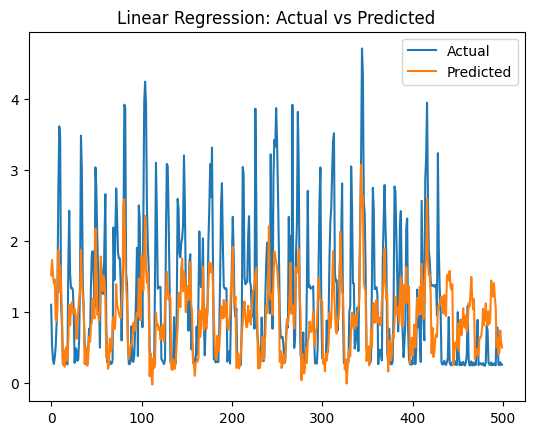

Linear Regression MAE: 0.575
Linear Regression RMSE: 0.744
Linear Regression R²: 0.351


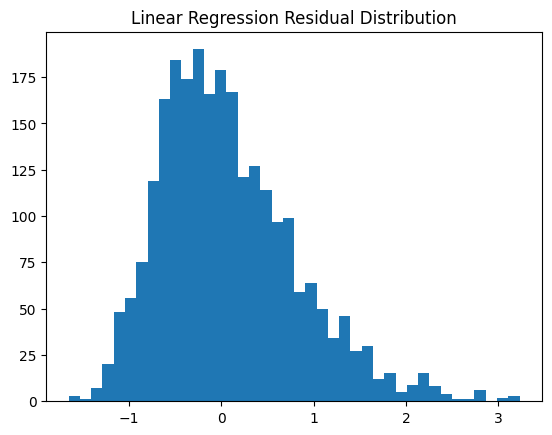

Mean Residual (LR): 0.0743


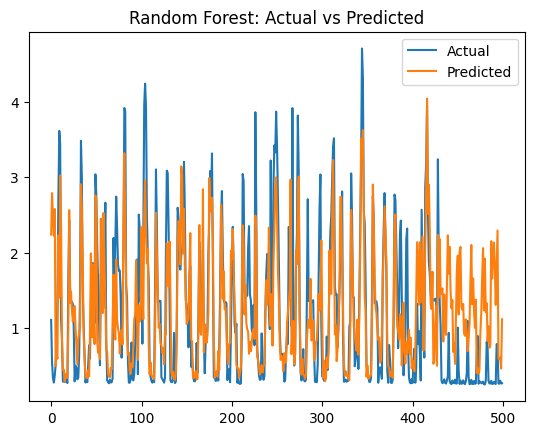

Random Forest MAE: 0.513
Random Forest RMSE: 0.723
Random Forest R²: 0.388


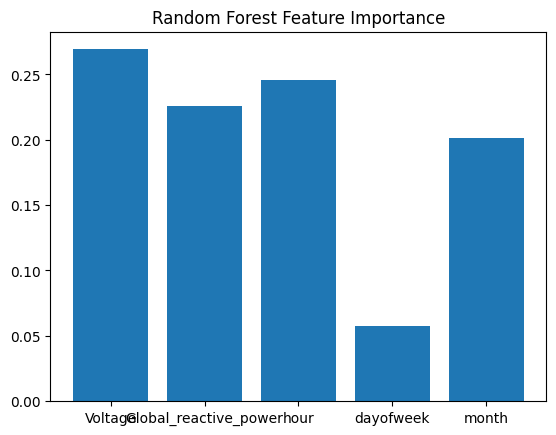

Voltage: 0.269
Global_reactive_power: 0.226
hour: 0.246
dayofweek: 0.057
month: 0.202


,Model,MAE,RMSE,R2
0,Linear Regression,0.575098,0.744353,0.350868
1,Random Forest,0.513056,0.722776,0.387957


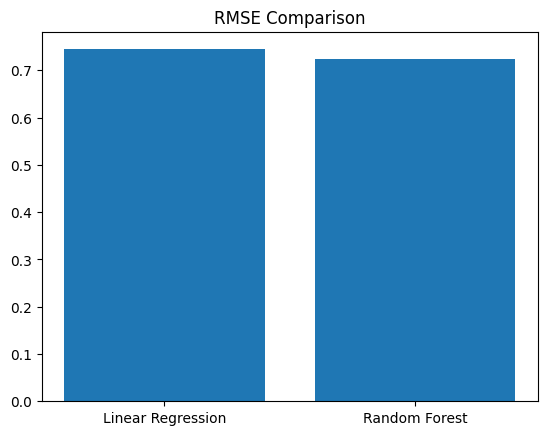

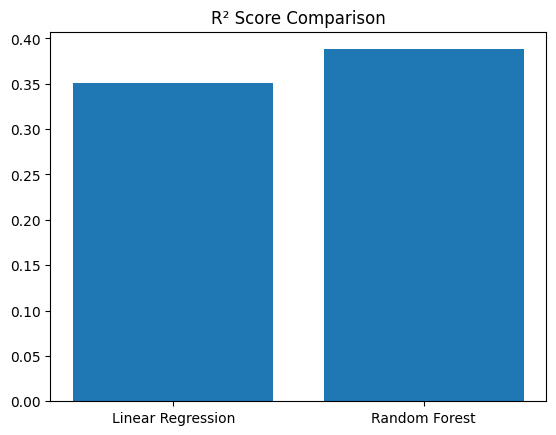

Best Model based on RMSE: Random Forest


In [4]:

# Time-Series Forecasting for Household Energy Consumption
# Machine Learning Fundamentals – Practical Skills Assessment



# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings("ignore")


# 2. LOAD DATA

file_path = "/content/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values="?",
    low_memory=False
)

print("Original Dataset Shape:", df.shape)


# 3. DATA PREPROCESSING


# Convert Date & Time to Datetime
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

df.drop(["Date", "Time"], axis=1, inplace=True)
df.set_index("Datetime", inplace=True)

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors="coerce")

print("\nMissing values BEFORE cleaning:")
print(df.isnull().sum())

# Drop original missing rows
df = df.dropna()

print("\nDataset shape after initial cleaning:", df.shape)


# 4. RESAMPLING (HOURLY)

df_hourly = df.resample("h").mean()

# Handle NaNs introduced by resampling
df_hourly = df_hourly.ffill().bfill()

# Final safety check
df_hourly = df_hourly.dropna()

print("\nHourly dataset shape after NaN handling:", df_hourly.shape)
print("Any NaNs left?", df_hourly.isnull().sum().sum())


# SECTION 1: EXPLORATORY DATA ANALYSIS (EDA)


# ---- Graph 1: Global Active Power over time ----
plt.figure()
plt.plot(df_hourly.index, df_hourly["Global_active_power"])
mean_gap = df_hourly["Global_active_power"].mean()
plt.axhline(mean_gap)
plt.title("Hourly Global Active Power Consumption")
plt.xlabel("Time")
plt.ylabel("kW")
plt.show()

print("Mean Global Active Power (kW):", round(mean_gap, 3))

# ---- Graph 2: Voltage over time ----
plt.figure()
plt.plot(df_hourly.index, df_hourly["Voltage"])
mean_voltage = df_hourly["Voltage"].mean()
plt.axhline(mean_voltage)
plt.title("Hourly Voltage Trend")
plt.xlabel("Time")
plt.ylabel("Voltage (V)")
plt.show()

print("Mean Voltage (V):", round(mean_voltage, 2))


# SECTION 2: SEASONALITY & DISTRIBUTION


# ---- Graph 1: Hourly average consumption ----
hourly_avg = df_hourly.groupby(df_hourly.index.hour)["Global_active_power"].mean()

plt.figure()
plt.plot(hourly_avg.index, hourly_avg.values)
plt.title("Average Power Consumption by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("kW")
plt.show()

print("Peak Hour Consumption (kW):", round(hourly_avg.max(), 3))

# ---- Graph 2: Distribution ----
plt.figure()
plt.hist(df_hourly["Global_active_power"], bins=40)
plt.title("Distribution of Global Active Power")
plt.xlabel("kW")
plt.ylabel("Frequency")
plt.show()

print("Median Power Consumption (kW):", round(df_hourly["Global_active_power"].median(), 3))


# SECTION 3: FEATURE ENGINEERING


df_feat = df_hourly.copy()

df_feat["hour"] = df_feat.index.hour
df_feat["dayofweek"] = df_feat.index.dayofweek
df_feat["month"] = df_feat.index.month

# ---- Graph 1: Day-of-week trend ----
weekday_avg = df_feat.groupby("dayofweek")["Global_active_power"].mean()

plt.figure()
plt.plot(weekday_avg.index, weekday_avg.values)
plt.title("Average Consumption by Day of Week (0=Mon)")
plt.xlabel("Day")
plt.ylabel("kW")
plt.show()

print("Highest weekday consumption (kW):", round(weekday_avg.max(), 3))

# ---- Graph 2: Monthly trend ----
monthly_avg = df_feat.groupby("month")["Global_active_power"].mean()

plt.figure()
plt.plot(monthly_avg.index, monthly_avg.values)
plt.title("Average Monthly Power Consumption")
plt.xlabel("Month")
plt.ylabel("kW")
plt.show()

print("Highest monthly consumption (kW):", round(monthly_avg.max(), 3))


# SECTION 4: TRAIN–TEST SPLIT


target = "Global_active_power"
features = ["Voltage", "Global_reactive_power", "hour", "dayofweek", "month"]

X = df_feat[features]
y = df_feat[target]

# Final NaN safety check (critical)
assert X.isnull().sum().sum() == 0, "NaNs found in features!"
assert y.isnull().sum() == 0, "NaNs found in target!"

split_index = int(len(df_feat) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


# SECTION 5: MODEL 1 – LINEAR REGRESSION


lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# ---- Graph 1: Actual vs Predicted ----
plt.figure()
plt.plot(y_test.values[:500], label="Actual")
plt.plot(y_pred_lr[:500], label="Predicted")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()

print("Linear Regression MAE:", round(mae_lr, 3))
print("Linear Regression RMSE:", round(rmse_lr, 3))
print("Linear Regression R²:", round(r2_lr, 3))

# ---- Graph 2: Residuals ----
residuals_lr = y_test - y_pred_lr

plt.figure()
plt.hist(residuals_lr, bins=40)
plt.title("Linear Regression Residual Distribution")
plt.show()

print("Mean Residual (LR):", round(residuals_lr.mean(), 4))


# SECTION 6: MODEL 2 – RANDOM FOREST


rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# ---- Graph 1: Actual vs Predicted ----
plt.figure()
plt.plot(y_test.values[:500], label="Actual")
plt.plot(y_pred_rf[:500], label="Predicted")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.show()

print("Random Forest MAE:", round(mae_rf, 3))
print("Random Forest RMSE:", round(rmse_rf, 3))
print("Random Forest R²:", round(r2_rf, 3))

# ---- Graph 2: Feature Importance ----
importances = rf.feature_importances_

plt.figure()
plt.bar(features, importances)
plt.title("Random Forest Feature Importance")
plt.show()

for f, imp in zip(features, importances):
    print(f"{f}: {round(imp, 3)}")


# SECTION 7: MODEL COMPARISON


results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_lr, mae_rf],
    "RMSE": [rmse_lr, rmse_rf],
    "R2": [r2_lr, r2_rf]
})

display(results)

# ---- Graph 1: RMSE comparison ----
plt.figure()
plt.bar(results["Model"], results["RMSE"])
plt.title("RMSE Comparison")
plt.show()

# ---- Graph 2: R² comparison ----
plt.figure()
plt.bar(results["Model"], results["R2"])
plt.title("R² Score Comparison")
plt.show()

print("Best Model based on RMSE:", results.loc[results["RMSE"].idxmin(), "Model"])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

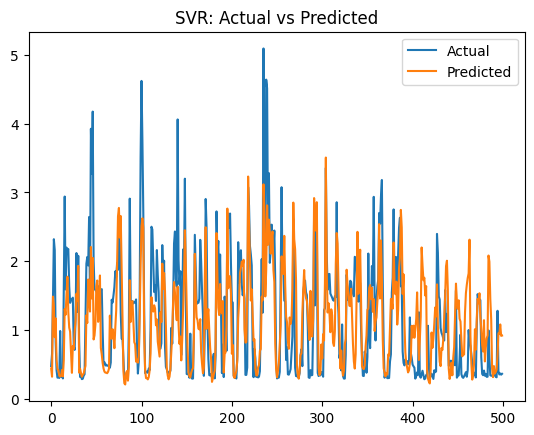

SVR MAE: 0.428
SVR MSE: 0.353
SVR RMSE: 0.594
SVR R²: 0.337


In [ ]:
# Model 3 – Support Vector Regression (SVR)


# SECTION 6 (ADDITION): MODEL 3 – SUPPORT VECTOR REGRESSION

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf", C=10, epsilon=0.1))
])

svr_model.fit(X_train, y_train)

y_pred_svr = svr_model.predict(X_test)

# Evaluation metrics
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

# ---- Graph: Actual vs Predicted ----
plt.figure()
plt.plot(y_test.values[:500], label="Actual")
plt.plot(y_pred_svr[:500], label="Predicted")
plt.title("SVR: Actual vs Predicted")
plt.legend()
plt.show()

print("SVR MAE:", round(mae_svr, 3))
print("SVR MSE:", round(mse_svr, 3))
print("SVR RMSE:", round(rmse_svr, 3))
print("SVR R²:", round(r2_svr, 3))


In [ ]:
# MSE for Linear Regression


mse_lr = mean_squared_error(y_test, y_pred_lr)
print("Linear Regression MSE:", round(mse_lr, 3))


Linear Regression MSE: 0.41


In [ ]:
# MSE for Random Forest

mse_rf = mean_squared_error(y_test, y_pred_rf)
print("Random Forest MSE:", round(mse_rf, 3))


Random Forest MSE: 0.327


In [ ]:
# UPDATED MODEL COMPARISON TABLE


results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "SVR"],
    "MAE": [mae_lr, mae_rf, mae_svr],
    "MSE": [mse_lr, mse_rf, mse_svr],
    "RMSE": [rmse_lr, rmse_rf, rmse_svr],
    "R2": [r2_lr, r2_rf, r2_svr]
})

display(results)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.520050,0.409919,0.640249,0.230381
1,Random Forest,0.412077,0.327133,0.571956,0.385811
2,SVR,0.427604,0.353249,0.594348,0.336778
